# Benchmark HDFS vs Apache Ozone — Prestazioni e storage

Quattro dimensioni (10 KiB, 50 MiB, 250 MiB e 1 GiB), **5 ripetizioni per sistema**, con nomi remoti differenti per ogni upload, mantenendo lo stesso contenuto per dimensione.

Per ciascuna ripetizione misuriamo lo storage **prima e dopo** l’upload (fuori dal cronometro), poi scarichiamo e verifichiamo SHA-256. Gli oggetti restano memorizzati fino alla fine; non lanciare altri benchmark contemporaneamente.

In [1]:
from src.benchmark import BenchmarkConfig, run_benchmark, plot_storage_results
from src.storage_analysis import snapshot

config = BenchmarkConfig(repetitions=5, clean_remote=False, settle_seconds=2.0)
print(config)
print("Volumi accessibili:", ", ".join(snapshot()))

BenchmarkConfig(repetitions=5, results_dir=PosixPath('/home/jovyan/work/results'), hdfs_prefix='/benchmark/performance', ozone_prefix='performance', ozone_bucket='asdbd-benchmark', clean_remote=False, settle_seconds=2.0)
Volumi accessibili: hdfs_name, hdfs_dn1, hdfs_dn2, hdfs_dn3, ozone_scm, ozone_om, ozone_dn, ozone_recon


## Esecuzione integrale e ripresa

Ogni upload usa una chiave unica. Le rilevazioni sono salvate dopo la verifica del download.

**Attenzione:** se l’esecuzione si interrompe dopo aver caricato un file ma prima di averne registrato il risultato, la ripresa si fermerà per non sovrascrivere l’oggetto e alterare il delta di storage. In quel caso ispeziona i file prima di decidere come procedere.

Per un nuovo benchmark non riutilizzare `run_id` precedenti. La misura iniziale viene conservata nel file `*_storage_baseline.json`.

In [2]:
# Inserire un run_id esistente SOLO per riprendere una sessione con gli stessi parametri.
run_id_da_riprendere = None
risultato = run_benchmark(config, run_id=run_id_da_riprendere)
print("Run ID:", risultato["run_id"])
print("CSV grezzo:", risultato["raw_csv"])
print("CSV riepilogo:", risultato["summary_csv"])

Controllo/generazione dei file originali (fuori dal benchmark)...
[RIUTILIZZATO] benchmark_10KiB.bin
[RIUTILIZZATO] benchmark_50MiB.bin
[RIUTILIZZATO] benchmark_250MiB.bin
[RIUTILIZZATO] benchmark_1GiB.bin

Manifest salvato in: /home/jovyan/work/results/generated_files.json
[TEST] HDFS  10KiB  rip. 1/5
       upload=1.037s download=0.081s checksum=OK (1/40)
[TEST] Ozone 10KiB  rip. 1/5
       upload=1.035s download=0.244s checksum=OK (2/40)
[TEST] Ozone 10KiB  rip. 2/5
       upload=0.090s download=0.069s checksum=OK (3/40)
[TEST] HDFS  10KiB  rip. 2/5
       upload=0.903s download=0.064s checksum=OK (4/40)
[TEST] HDFS  10KiB  rip. 3/5
       upload=0.046s download=0.041s checksum=OK (5/40)
[TEST] Ozone 10KiB  rip. 3/5
       upload=0.112s download=0.067s checksum=OK (6/40)
[TEST] Ozone 10KiB  rip. 4/5
       upload=0.053s download=0.070s checksum=OK (7/40)
[TEST] HDFS  10KiB  rip. 4/5
       upload=0.895s download=0.090s checksum=OK (8/40)
[TEST] HDFS  10KiB  rip. 5/5
       upload=0.

## Tabella comparativa

I valori in secondi rappresentano le medie delle ripetizioni riuscite. Controllare che `completed` sia uguale a 5 per ogni combinazione.

In [3]:
import pandas as pd
riepilogo = pd.read_csv(risultato["summary_csv"])
display(riepilogo)
assert len(riepilogo) == 8 and (riepilogo["completed"] == config.repetitions).all()

,run_id,size_label,size_bytes,system,completed,upload_mean_s,upload_median_s,upload_stdev_s,download_mean_s,download_median_s,download_stdev_s,upload_mean_mib_s,download_mean_mib_s
0,20261011T105223Z-e627ad,10KiB,10240,HDFS,5,0.584320,0.894981,0.496874,0.061834,0.064097,0.024517,0.0962,0.1826
1,20261011T105223Z-e627ad,10KiB,10240,Ozone,5,0.268810,0.089941,0.429293,0.101328,0.068878,0.079909,0.1142,0.1278
2,20261011T105223Z-e627ad,50MiB,52428800,HDFS,5,1.444484,1.380796,0.334188,0.480603,0.469332,0.041846,36.0496,104.6427
3,20261011T105223Z-e627ad,50MiB,52428800,Ozone,5,1.554218,1.545629,0.112512,0.938982,0.927971,0.096657,32.3041,53.6710
4,20261011T105223Z-e627ad,250MiB,262144000,HDFS,5,6.169004,6.514772,0.998803,2.196177,2.124843,0.183135,41.4171,114.4357
5,20261011T105223Z-e627ad,250MiB,262144000,Ozone,5,7.583388,7.488827,0.482759,4.916381,4.749244,0.627989,33.0768,51.4748
6,20261011T105223Z-e627ad,1GiB,1073741824,HDFS,5,27.890676,27.918950,1.204895,9.738951,9.784633,1.021643,36.7696,106.0364
7,20261011T105223Z-e627ad,1GiB,1073741824,Ozone,5,32.139211,31.715682,1.589919,23.440001,23.702756,1.472161,31.9225,43.8221


## Grafici di confronto

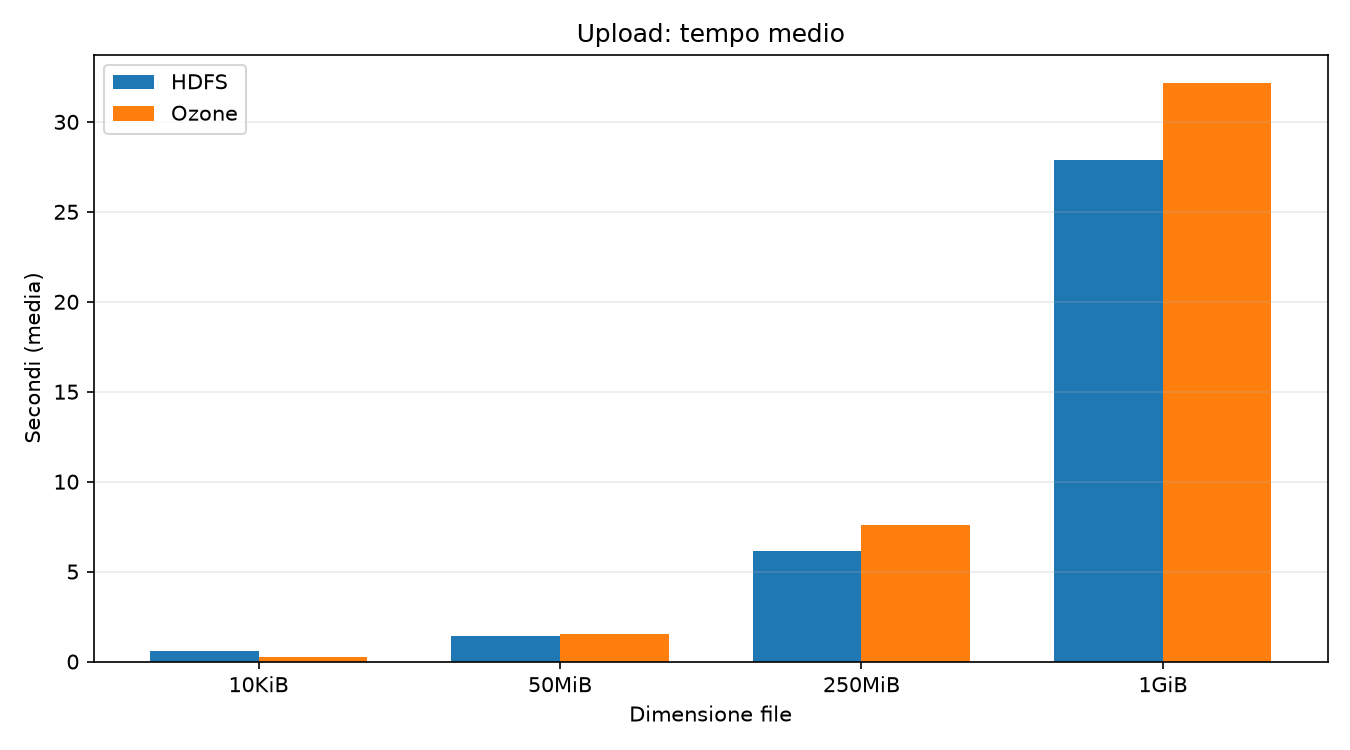

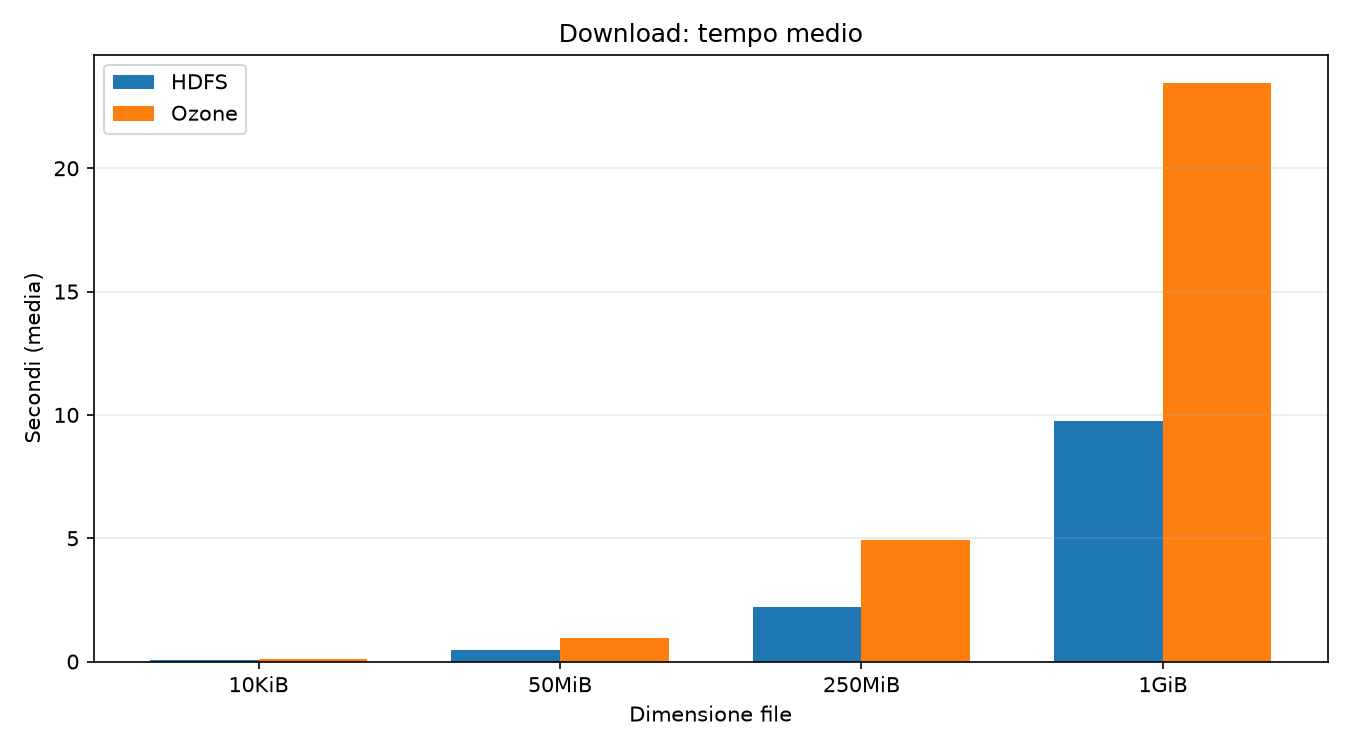

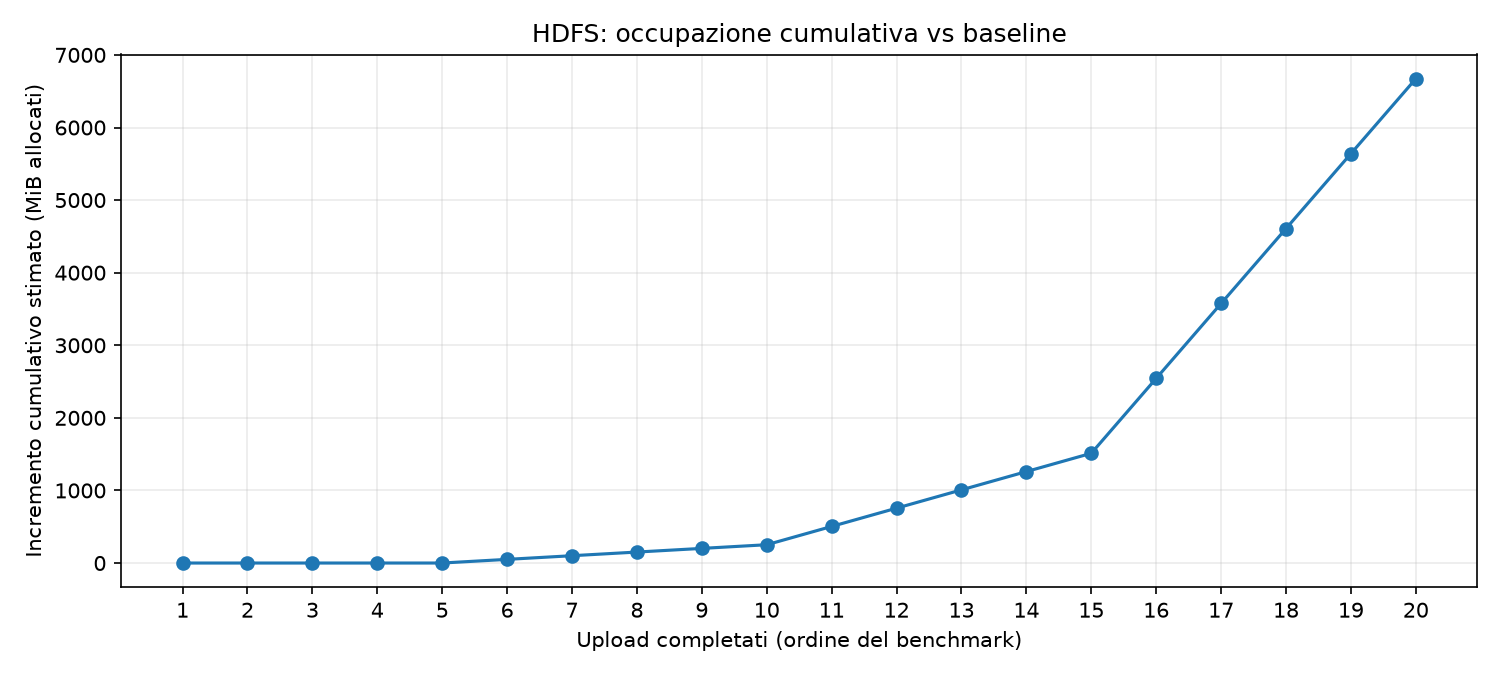

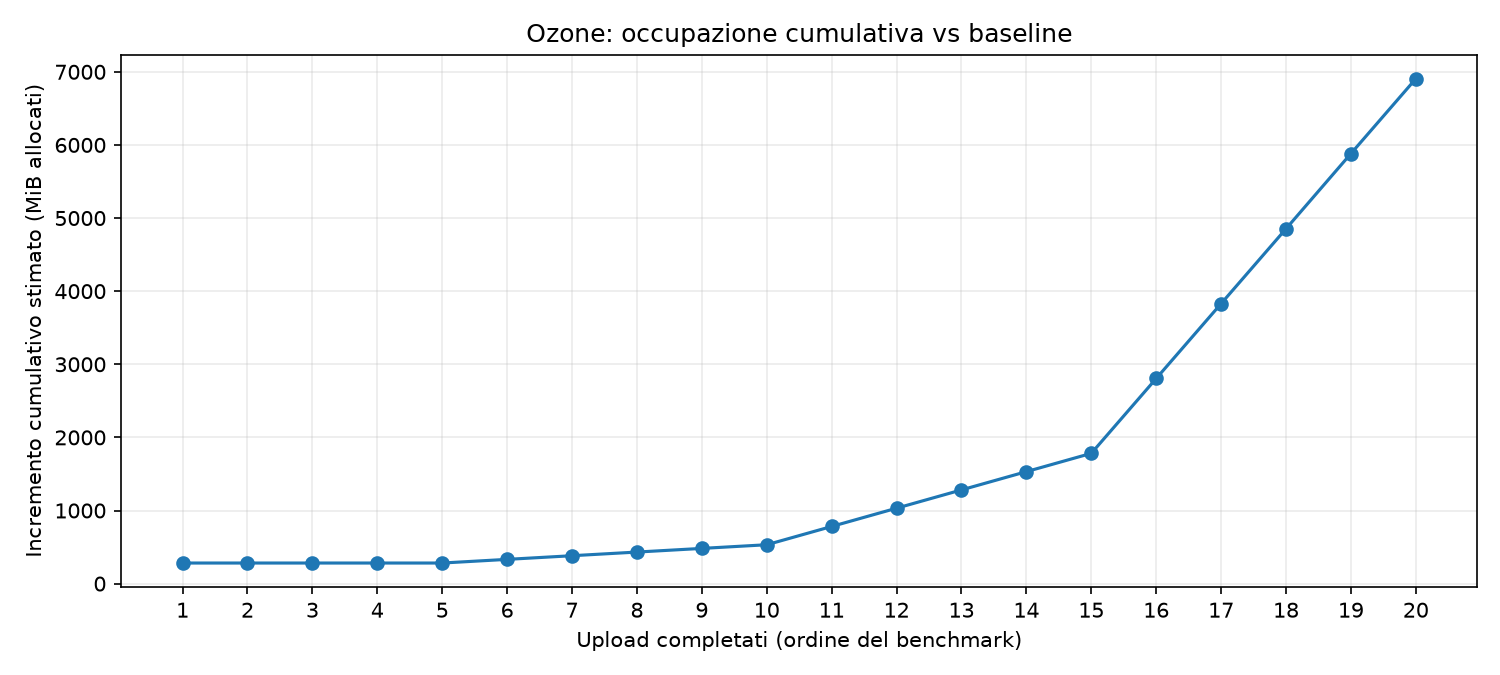

In [4]:
from IPython.display import Image, display

for grafico in risultato["plots"]:
    display(Image(filename=grafico))

## Integrità e numero di misure

In [5]:
grezzi = pd.read_csv(risultato["raw_csv"])
print("Cicli verificati:", len(grezzi), "/ 40")
print("SHA-256 validi:", grezzi["verified"].all())
assert len(grezzi) == 40 and grezzi["verified"].all()

Cicli verificati: 40 / 40
SHA-256 validi: True


## Analisi dell’occupazione dello storage

Le seguenti metriche sono state raccolte **durante gli stessi 40 cicli**, senza nuovi upload: spazio iniziale e finale, delta dei volumi DataNode, delta dei metadati, incremento cumulativo rispetto alla baseline.

**Limiti:** si sommano i byte allocati (`st_blocks × 512`) nei file dei volumi, non i settori fisici reali. Ozone può preallocare/riutilizzare container e aggiornare metadati in modo asincrono. Il `delta` non è sempre equivalente a “dimensione file + overhead”. Le misure sono sensibili ai carichi concorrenti.

In [5]:
grezzi = pd.read_csv(risultato["raw_csv"])
colonne = ["system", "size_label", "repeat", "storage_before_bytes", "storage_after_bytes", "storage_delta_bytes", "storage_cumulative_bytes", "storage_data_delta_bytes", "storage_metadata_delta_bytes", "storage_overhead_pct"]
display(grezzi[colonne])
assert len(grezzi) == 4 * 2 * config.repetitions


,system,size_label,repeat,storage_before_bytes,storage_after_bytes,storage_delta_bytes,storage_cumulative_bytes,storage_data_delta_bytes,storage_metadata_delta_bytes,storage_overhead_pct
0,HDFS,10KiB,1,12601651200,12601667584,16384,16384,16384,0,60.000
1,Ozone,10KiB,1,13286662144,13581959168,295297024,295297024,147656704,147640320,2883660.000
2,Ozone,10KiB,2,13581959168,13581975552,16384,295313408,16384,0,60.000
3,HDFS,10KiB,2,12601667584,12601683968,16384,32768,16384,0,60.000
4,HDFS,10KiB,3,12601683968,12601700352,16384,49152,16384,0,60.000
5,Ozone,10KiB,3,13581975552,13581987840,12288,295325696,12288,0,20.000
6,Ozone,10KiB,4,13581987840,13582000128,12288,295337984,12288,0,20.000
7,HDFS,10KiB,4,12601700352,12601716736,16384,65536,16384,0,60.000
8,HDFS,10KiB,5,12601716736,12601733120,16384,81920,16384,0,60.000
9,Ozone,10KiB,5,13582000128,13582012416,12288,295350272,12288,0,20.000


## Grafici della crescita cumulativa

I valori sono separati per HDFS e Ozone e fanno riferimento alla prima fotografia dei rispettivi volumi. Non interpretarli come capacità fisiche indipendenti del computer.

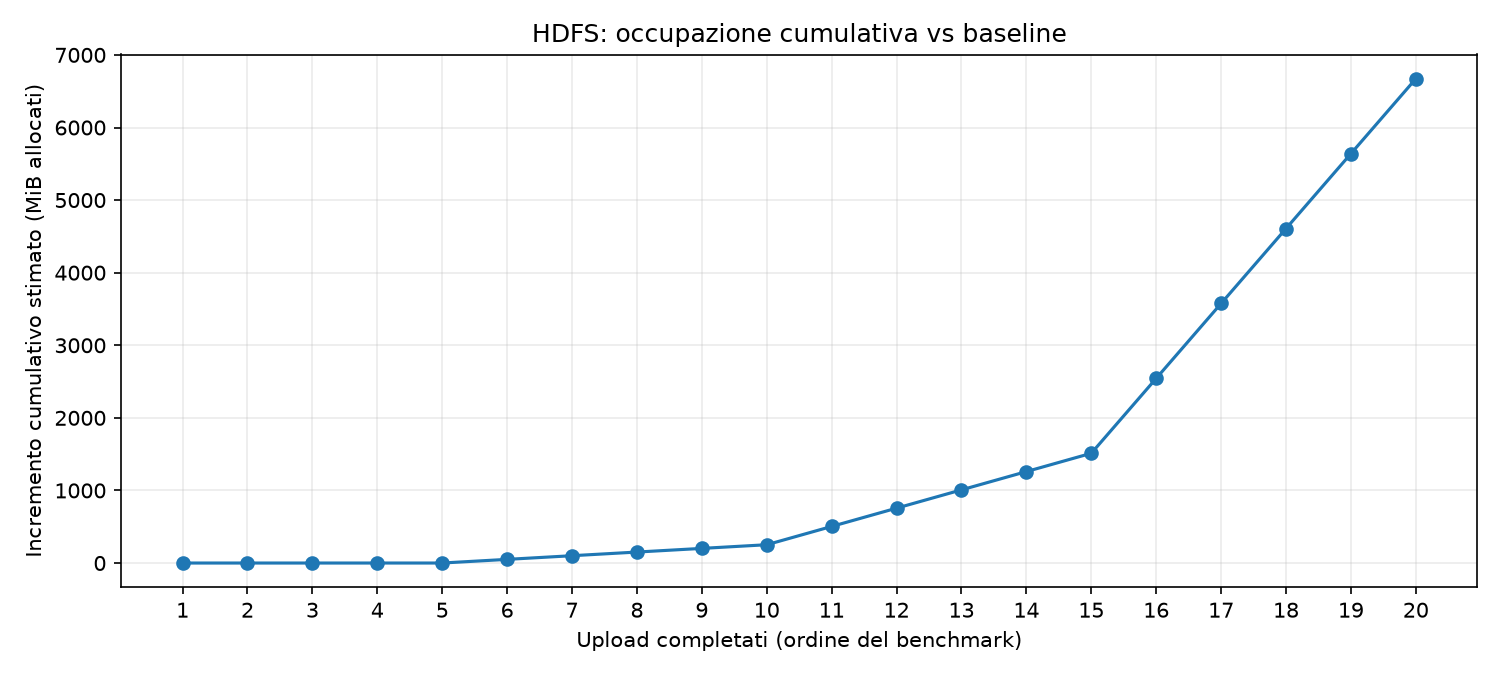

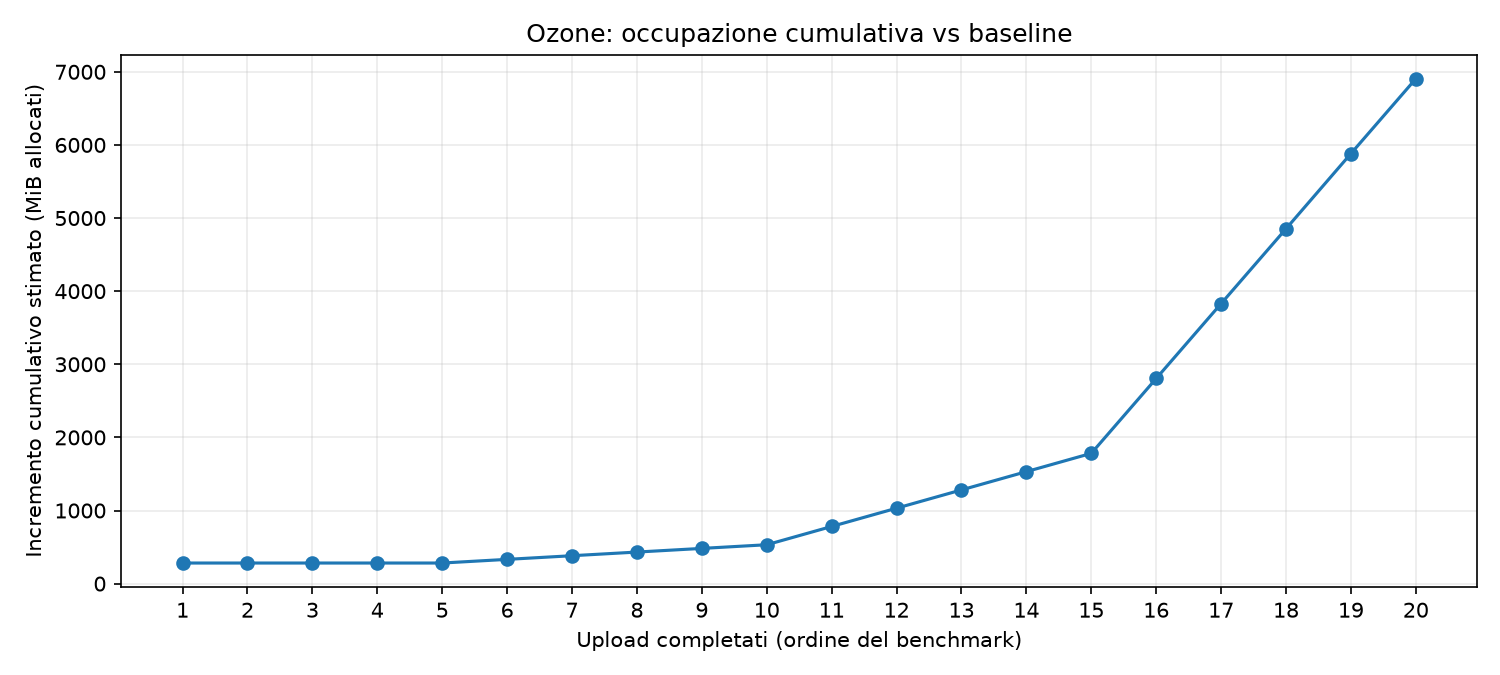

In [6]:
from IPython.display import display, Image
for percorso in plot_storage_results(risultato["run_id"], results_dir=config.results_dir):
    display(Image(filename=str(percorso)))